# 08 - Final Report

## Ziel
Dieses Notebook fasst die Ergebnisse der vorherigen Analysen in einem managementtauglichen Abschlussbericht zusammen.

## Management-Fragen
- Wie ist das Risikoportfolio strukturiert?
- Wie unterscheiden sich altes Score-System, neues Score-System und ML-Modell?
- Welche wirtschaftlichen Auswirkungen ergeben sich?
- Welche Fairness-Risiken bestehen?
- Welche konkrete Empfehlung lässt sich für den praktischen Einsatz ableiten?

## Zielgruppen
- Bank
- Versicherung
- Recruiter / Hiring Manager
- Fachbereich / Management

## Ergebnis
Am Ende steht ein klarer Abschlussbericht mit:
- Executive Summary
- Portfolio-Überblick
- Score- und Modellvergleich
- Business-Impact
- Fairness-Analyse
- Handlungsempfehlungen
- Limitations
- Exportierbaren Report-Dateien

# Fazit

Dieses Notebook übersetzt die technischen Ergebnisse des Projekts in eine managementtaugliche Form.

## Kernaussage
Das Projekt zeigt, dass Kreditrisikomodelle nicht nur nach Modellgüte,
sondern auch nach wirtschaftlicher Wirkung und Fairness bewertet werden müssen.

## Projektstärke
Die Kombination aus:
- Datenanalyse
- Scoring-Vergleich
- Machine Learning
- Modellinterpretation
- Fairness
- Business Impact
- Management-Reporting

macht das Gesamtprojekt sehr stark für Bank, Versicherung

In [33]:
import warnings
warnings.filterwarnings("ignore")

import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

## 1. Dateien hochladen

Bitte lade möglichst die Ergebnisse aus den vorherigen Notebooks hoch.

### Pflicht
- Hauptdatensatz / Modellierungsdatensatz als CSV

### Optional, aber sehr hilfreich
- `income_fairness.csv`
- `age_fairness.csv`
- `score_fairness.csv`
- `strategy_results.csv`
- `threshold_scenarios.csv`
- `fairness_business_summary.csv`

Das Notebook funktioniert auch, wenn nicht alle Dateien vorliegen.

In [35]:
uploaded = files.upload()

def read_csv_flexible(file_bytes):
    try:
        df_temp = pd.read_csv(io.BytesIO(file_bytes), sep=",")
        if df_temp.shape[1] == 1:
            df_temp = pd.read_csv(io.BytesIO(file_bytes), sep=";")
    except:
        df_temp = pd.read_csv(io.BytesIO(file_bytes), sep=";")
    return df_temp

loaded_files = {}

for fname, fbytes in uploaded.items():
    try:
        loaded_files[fname] = read_csv_flexible(fbytes)
        print(f"Geladen: {fname} | Shape: {loaded_files[fname].shape}")
    except Exception as e:
        print(f"Fehler bei {fname}: {e}")

print("\nVerfügbare Dateien:")
print(list(loaded_files.keys()))

Saving age_fairness.csv to age_fairness (1).csv
Saving credit_score_dataset_cleaned.csv to credit_score_dataset_cleaned (1).csv
Saving fairness_business_summary.csv to fairness_business_summary (1).csv
Saving final_management_report.txt to final_management_report (1).txt
Saving final_report_kpis.csv to final_report_kpis (1).csv
Saving income_fairness.csv to income_fairness (1).csv
Saving score_fairness.csv to score_fairness (1).csv
Saving scoring_comparison_results.csv to scoring_comparison_results (1).csv
Saving strategy_results.csv to strategy_results (1).csv
Saving synthetic_schufa_dataset.csv to synthetic_schufa_dataset (1).csv
Saving threshold_scenarios.csv to threshold_scenarios (1).csv
Geladen: age_fairness (1).csv | Shape: (4, 9)
Geladen: credit_score_dataset_cleaned (1).csv | Shape: (10000, 21)
Geladen: fairness_business_summary (1).csv | Shape: (7, 2)
Geladen: final_management_report (1).txt | Shape: (79, 1)
Geladen: final_report_kpis (1).csv | Shape: (9, 3)
Geladen: income_f

## 2. Hauptdatensatz automatisch bestimmen

In [36]:
candidate_columns = [
    "default",
    "old_score",
    "new_score",
    "credit_amount",
    "net_income"
]

main_df_name = None
best_score = -1

for fname, temp_df in loaded_files.items():
    score = sum(col in temp_df.columns for col in candidate_columns)
    if score > best_score:
        best_score = score
        main_df_name = fname

if main_df_name is None:
    raise ValueError("Keine geeignete Hauptdatei gefunden.")

df = loaded_files[main_df_name].copy()

print("Verwendete Hauptdatei:", main_df_name)
print("Shape:", df.shape)
print("\nSpalten:")
print(df.columns.tolist())
df.head()

Verwendete Hauptdatei: credit_score_dataset_cleaned (1).csv
Shape: (10000, 21)

Spalten:
['age', 'net_income', 'employment_status', 'marital_status', 'dependents', 'monthly_expenses', 'existing_loans', 'credit_amount', 'debt_to_income', 'late_payments', 'hard_inquiries', 'credit_history_years', 'negative_entry', 'collection_cases', 'bank_balance', 'liquidity_ratio', 'old_score', 'new_score', 'credit_approved_old_system', 'credit_approved_new_system', 'default']


,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default
0,56,"1,777.1400",selbstständig,verheiratet,0,855.6400,2,"8,894.4000",0.4200,0,1,9.2000,0,0,"4,301.2500",5.0300,100.0000,100.0000,1,1,0
1,69,"3,370.4400",teilzeit,verheiratet,0,"1,584.9800",1,"19,110.7700",0.4700,0,0,9.6000,0,0,"3,233.9700",2.0400,100.0000,100.0000,0,1,0
2,46,"3,558.9500",arbeitslos,geschieden,0,"2,547.6800",1,"15,440.4700",0.3600,2,2,10.8000,0,0,-409.9500,-0.1600,93.8000,100.0000,1,1,1
3,32,"2,230.9900",selbstständig,ledig,0,"1,066.7000",1,"5,273.9700",0.2000,0,2,5.6000,0,0,"-1,898.4700",-1.7800,98.6000,100.0000,1,1,0
4,60,"1,873.8700",teilzeit,ledig,1,"1,343.8700",3,"8,439.6100",0.3800,2,1,8.6000,0,0,"1,761.9800",1.3100,96.7000,99.4000,1,1,0


In [37]:
income_fairness = loaded_files.get("income_fairness.csv")
age_fairness = loaded_files.get("age_fairness.csv")
score_fairness = loaded_files.get("score_fairness.csv")
strategy_results = loaded_files.get("strategy_results.csv")
scenario_df = loaded_files.get("threshold_scenarios.csv")
summary_table = loaded_files.get("fairness_business_summary.csv")

print("income_fairness:", income_fairness is not None)
print("age_fairness:", age_fairness is not None)
print("score_fairness:", score_fairness is not None)
print("strategy_results:", strategy_results is not None)
print("threshold_scenarios:", scenario_df is not None)
print("fairness_business_summary:", summary_table is not None)

income_fairness: False
age_fairness: False
score_fairness: False
strategy_results: False
threshold_scenarios: False
fairness_business_summary: False


## 3. Portfolio- und Datenqualitätsüberblick

In [38]:
portfolio_summary = {
    "portfolio_size": len(df),
    "default_rate": df["default"].mean() if "default" in df.columns else np.nan,
    "avg_credit_amount": df["credit_amount"].mean() if "credit_amount" in df.columns else np.nan,
    "median_credit_amount": df["credit_amount"].median() if "credit_amount" in df.columns else np.nan,
    "avg_income": df["net_income"].mean() if "net_income" in df.columns else np.nan,
    "median_income": df["net_income"].median() if "net_income" in df.columns else np.nan,
    "avg_old_score": df["old_score"].mean() if "old_score" in df.columns else np.nan,
    "avg_new_score": df["new_score"].mean() if "new_score" in df.columns else np.nan,
    "missing_share_total": df.isna().mean().mean()
}

portfolio_summary_df = pd.DataFrame({
    "metric": portfolio_summary.keys(),
    "value": portfolio_summary.values()
})

portfolio_summary_df

,metric,value
0,portfolio_size,"10,000.0000"
1,default_rate,0.1301
2,avg_credit_amount,"11,950.0056"
3,median_credit_amount,"10,250.6150"
4,avg_income,"2,923.5201"
5,median_income,"2,874.8600"
6,avg_old_score,89.1180
7,avg_new_score,97.1086
8,missing_share_total,0.0000


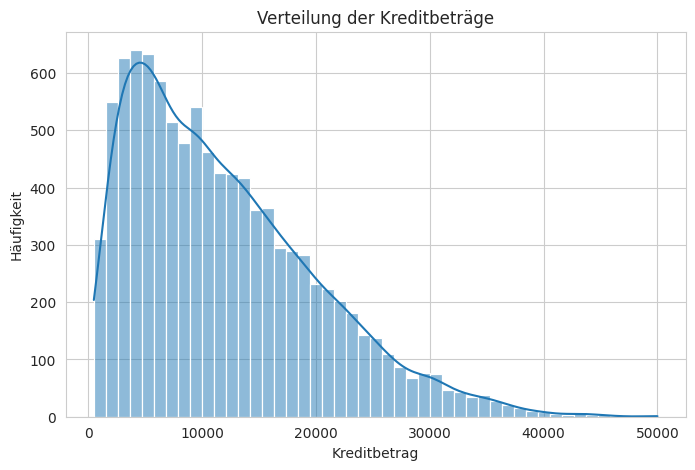

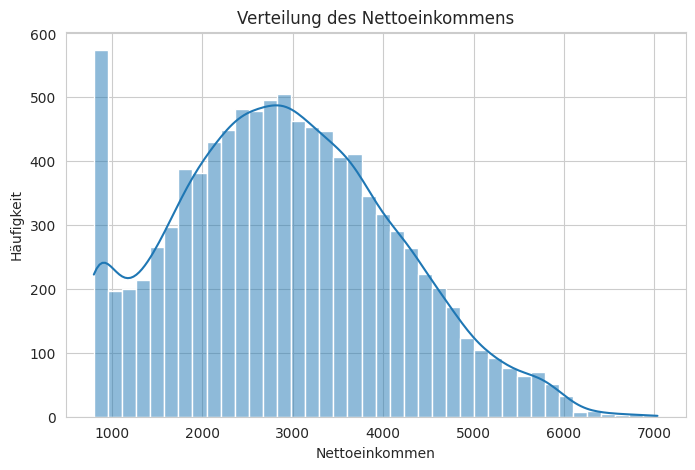

In [39]:
plt.figure(figsize=(8, 5))
sns.histplot(df["credit_amount"].dropna(), kde=True)
plt.title("Verteilung der Kreditbeträge")
plt.xlabel("Kreditbetrag")
plt.ylabel("Häufigkeit")
plt.show()

if "net_income" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(df["net_income"].dropna(), kde=True)
    plt.title("Verteilung des Nettoeinkommens")
    plt.xlabel("Nettoeinkommen")
    plt.ylabel("Häufigkeit")
    plt.show()

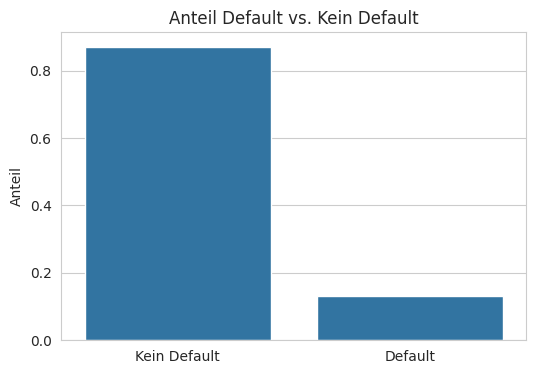

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
if "default" in df.columns:
    default_dist = df["default"].value_counts(normalize=True).sort_index()

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.barplot(x=["Kein Default", "Default"], y=default_dist.values, ax=ax)

    ax.set_title("Anteil Default vs. Kein Default")
    ax.set_ylabel("Anteil")

    file_name = "default_distribution.png"
    fig.savefig(file_name, bbox_inches="tight", dpi=300)

    plt.show()
    files.download(file_name)

## 4. Altes vs. neues Score-System

In [41]:
score_system_comparison = {}

if "credit_approved_old_system" in df.columns:
    score_system_comparison["approval_rate_old_system"] = df["credit_approved_old_system"].mean()

if "credit_approved_new_system" in df.columns:
    score_system_comparison["approval_rate_new_system"] = df["credit_approved_new_system"].mean()

if "default" in df.columns and "credit_approved_old_system" in df.columns:
    old_approved = df[df["credit_approved_old_system"] == 1]
    score_system_comparison["default_rate_old_approved"] = old_approved["default"].mean() if len(old_approved) > 0 else np.nan

if "default" in df.columns and "credit_approved_new_system" in df.columns:
    new_approved = df[df["credit_approved_new_system"] == 1]
    score_system_comparison["default_rate_new_approved"] = new_approved["default"].mean() if len(new_approved) > 0 else np.nan

score_system_comparison_df = pd.DataFrame({
    "metric": score_system_comparison.keys(),
    "value": score_system_comparison.values()
})

score_system_comparison_df

,metric,value
0,approval_rate_old_system,0.5999
1,approval_rate_new_system,0.7261
2,default_rate_old_approved,0.0833
3,default_rate_new_approved,0.0948


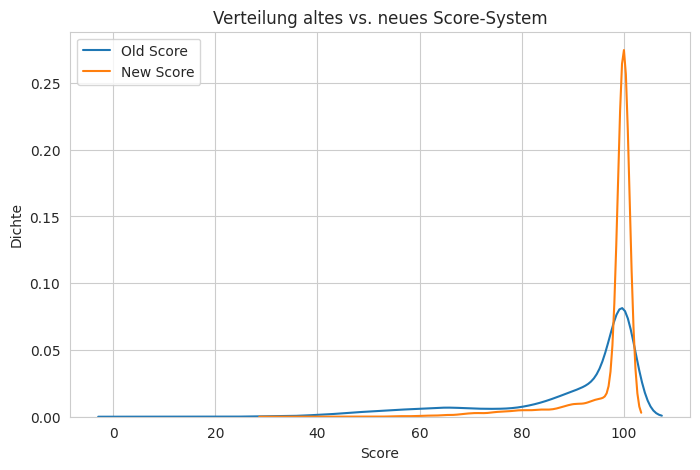

In [42]:
if {"old_score", "new_score"}.issubset(df.columns):
    plt.figure(figsize=(8, 5))
    sns.kdeplot(df["old_score"].dropna(), label="Old Score")
    sns.kdeplot(df["new_score"].dropna(), label="New Score")
    plt.title("Verteilung altes vs. neues Score-System")
    plt.xlabel("Score")
    plt.ylabel("Dichte")
    plt.legend()
    plt.show()

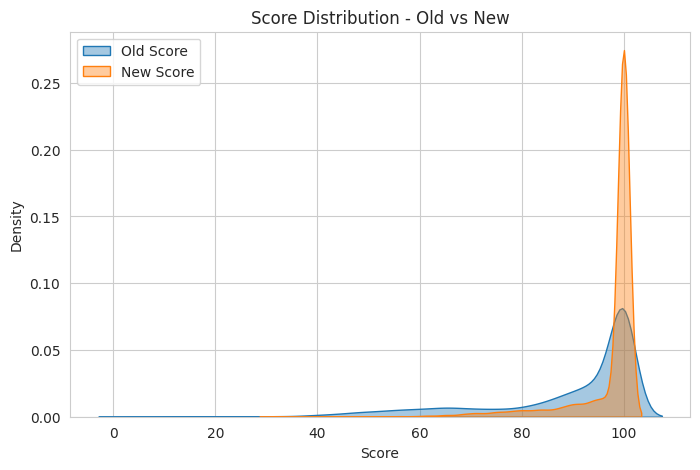

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:


fig, ax = plt.subplots(figsize=(8, 5))

sns.kdeplot(
    df["old_score"].dropna(),
    label="Old Score",
    fill=True,
    alpha=0.4,
    ax=ax
)

sns.kdeplot(
    df["new_score"].dropna(),
    label="New Score",
    fill=True,
    alpha=0.4,
    ax=ax
)

ax.set_title("Score Distribution - Old vs New")
ax.set_xlabel("Score")
ax.set_ylabel("Density")
ax.legend()

file_name = "score_distribution_old_vs_new.png"
fig.savefig(file_name, bbox_inches="tight", dpi=300)
plt.show()

files.download(file_name)

## 5. Strategievergleich

In [44]:
if strategy_results is not None:
    strategy_results_sorted = strategy_results.sort_values("total_profit", ascending=False).reset_index(drop=True)
    display(strategy_results_sorted)
else:
    print("strategy_results.csv nicht vorhanden.")

strategy_results.csv nicht vorhanden.


In [45]:
if strategy_results is not None:
    plt.figure(figsize=(9, 5))
    sns.barplot(data=strategy_results, x="strategy", y="total_profit")
    plt.title("Total Profit nach Strategie")
    plt.xlabel("Strategie")
    plt.ylabel("Total Profit")
    plt.xticks(rotation=20)
    plt.show()

    if "approval_rate" in strategy_results.columns:
        plt.figure(figsize=(9, 5))
        sns.barplot(data=strategy_results, x="strategy", y="approval_rate")
        plt.title("Approval Rate nach Strategie")
        plt.xlabel("Strategie")
        plt.ylabel("Approval Rate")
        plt.xticks(rotation=20)
        plt.show()

    if "income_approval_gap" in strategy_results.columns:
        plt.figure(figsize=(9, 5))
        sns.barplot(data=strategy_results, x="strategy", y="income_approval_gap")
        plt.title("Income Approval Gap nach Strategie")
        plt.xlabel("Strategie")
        plt.ylabel("Income Approval Gap")
        plt.xticks(rotation=20)
        plt.show()

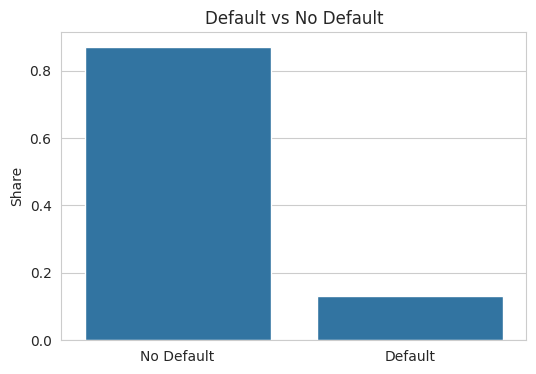

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:


default_dist = df["default"].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(6, 4))

sns.barplot(
    x=["No Default", "Default"],
    y=default_dist.values,
    ax=ax
)

ax.set_title("Default vs No Default")
ax.set_ylabel("Share")

file_name = "default_distribution.png"
fig.savefig(file_name, bbox_inches="tight", dpi=300)
plt.show()

files.download(file_name)

## 6. Threshold-Analyse

In [47]:
best_threshold_row = None

if scenario_df is not None and len(scenario_df) > 0:
    scenario_sorted = scenario_df.sort_values("total_profit", ascending=False).reset_index(drop=True)
    best_threshold_row = scenario_sorted.iloc[0]
    display(scenario_sorted.head(10))
else:
    print("threshold_scenarios.csv nicht vorhanden.")

threshold_scenarios.csv nicht vorhanden.


In [48]:
if scenario_df is not None:
    plt.figure(figsize=(8, 5))
    sns.lineplot(data=scenario_df, x="threshold", y="total_profit", marker="o")
    plt.title("Profit je Threshold")
    plt.xlabel("Threshold")
    plt.ylabel("Total Profit")
    plt.show()

    if "approval_rate" in scenario_df.columns:
        plt.figure(figsize=(8, 5))
        sns.lineplot(data=scenario_df, x="threshold", y="approval_rate", marker="o")
        plt.title("Approval Rate je Threshold")
        plt.xlabel("Threshold")
        plt.ylabel("Approval Rate")
        plt.show()

    if "income_approval_gap" in scenario_df.columns:
        plt.figure(figsize=(8, 5))
        sns.lineplot(data=scenario_df, x="threshold", y="income_approval_gap", marker="o")
        plt.title("Income Approval Gap je Threshold")
        plt.xlabel("Threshold")
        plt.ylabel("Income Approval Gap")
        plt.show()

In [49]:

# ============================================================
# BUSINESS SCENARIO ANALYSIS: PROFIT VS THRESHOLD
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# ------------------------------------------------------------
# 1) Daten und Zielvariable prüfen
# ------------------------------------------------------------
if "df" not in globals():
    raise NameError("'df' ist nicht definiert. Bitte zuerst den Hauptdatensatz laden.")

if "default" not in df.columns:
    raise KeyError("Die Zielvariable 'default' wurde im Hauptdatensatz nicht gefunden.")

# ------------------------------------------------------------
# 2) Features und Zielvariable vorbereiten
# ------------------------------------------------------------
X = df.drop(columns=["default"])
y = df["default"]

# Kategorische Features codieren
X = pd.get_dummies(X, drop_first=True)

# Nur numerische Werte zulassen und fehlende Werte bereinigen
X = X.replace([np.inf, -np.inf], np.nan)
valid_mask = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_mask]
y = y.loc[valid_mask]

# ------------------------------------------------------------
# 3) Train/Test-Split
# ------------------------------------------------------------
stratify_target = y if y.nunique() > 1 else None
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=stratify_target
)

# ------------------------------------------------------------
# 4) Random-Forest-Modell trainieren
# ------------------------------------------------------------
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)
rf_model.fit(X_train, y_train)

# ------------------------------------------------------------
# 5) Wahrscheinlichkeiten berechnen
# ------------------------------------------------------------
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]
print("Model ready ✅")
print("Erste 5 Wahrscheinlichkeiten:", y_proba_rf[:5])

# ------------------------------------------------------------
# 6) Threshold-Szenarien berechnen
#    pred == 0 wird hier als 'approve' interpretiert
# ------------------------------------------------------------
thresholds = np.arange(0.10, 1.00, 0.05)
profits = []
y_test_array = np.array(y_test)

for t in thresholds:
    y_pred = (y_proba_rf >= t).astype(int)
    profit = (
        ((y_pred == 0) & (y_test_array == 0)) * 1000 +
        ((y_pred == 0) & (y_test_array == 1)) * -5000
    ).sum()
    profits.append(profit)

scenario_df = pd.DataFrame({
    "threshold": thresholds,
    "total_profit": profits
})

print(scenario_df.head())


Model ready ✅
Erste 5 Wahrscheinlichkeiten: [0.58531143 0.2194013  0.24473397 0.41700991 0.18936554]
   threshold  total_profit
0     0.1000         37000
1     0.1500        164000
2     0.2000        255000
3     0.2500        357000
4     0.3000        519000


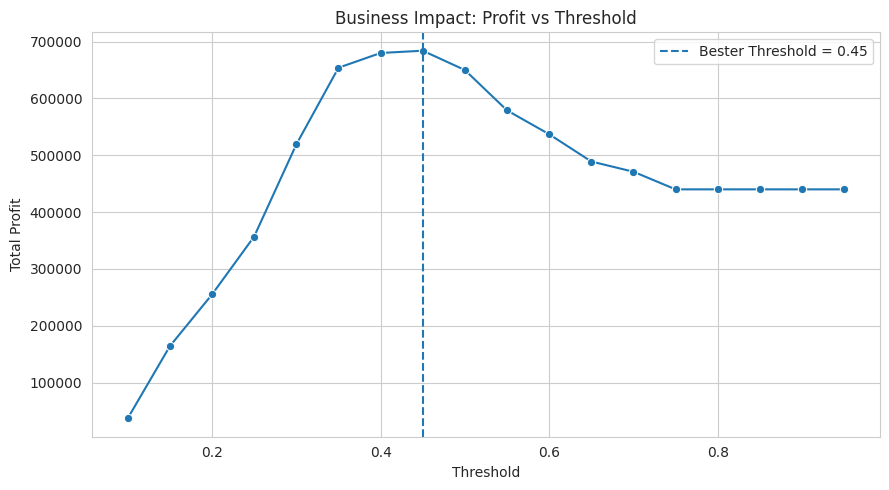

Bester Threshold: 0.45
Maximaler Profit: 684,000.00


In [50]:

# Beste Threshold-Einstellung bestimmen und visualisieren
best_row = scenario_df.loc[scenario_df["total_profit"].idxmax()]
best_threshold = float(best_row["threshold"])
best_profit = float(best_row["total_profit"])

plt.figure(figsize=(9, 5))
sns.lineplot(data=scenario_df, x="threshold", y="total_profit", marker="o")
plt.axvline(best_threshold, linestyle="--", label=f"Bester Threshold = {best_threshold:.2f}")
plt.title("Business Impact: Profit vs Threshold")
plt.xlabel("Threshold")
plt.ylabel("Total Profit")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Bester Threshold: {best_threshold:.2f}")
print(f"Maximaler Profit: {best_profit:,.2f}")


## 7. Fairness-Zusammenfassung

In [51]:
def extract_fairness_overview(fair_df, group_name):
    if fair_df is None or len(fair_df) == 0:
        return None

    result = {
        "group_type": group_name,
        "max_approval_rate": fair_df["approval_rate"].max() if "approval_rate" in fair_df.columns else np.nan,
        "min_approval_rate": fair_df["approval_rate"].min() if "approval_rate" in fair_df.columns else np.nan,
        "approval_gap": (
            fair_df["approval_rate"].max() - fair_df["approval_rate"].min()
            if "approval_rate" in fair_df.columns else np.nan
        ),
        "max_fpr": fair_df["fpr"].max() if "fpr" in fair_df.columns else np.nan,
        "min_fpr": fair_df["fpr"].min() if "fpr" in fair_df.columns else np.nan,
    }
    return result

fairness_rows = []

for fair_df, group_name in [
    (income_fairness, "income"),
    (age_fairness, "age"),
    (score_fairness, "score")
]:
    row = extract_fairness_overview(fair_df, group_name)
    if row is not None:
        fairness_rows.append(row)

fairness_overview_df = pd.DataFrame(fairness_rows)
fairness_overview_df

""


In [55]:

# Robuste Fairness-Plots

def ensure_group_column(fair_df, fallback_name=None):
    if fair_df is None or len(fair_df) == 0:
        return fair_df
    fair_df = fair_df.copy()
    if "group" not in fair_df.columns:
        candidate_cols = [
            c for c in fair_df.columns
            if c.lower() in [
                "income_group", "age_group", "score_group", "group_name",
                "segment", "bucket", "category"
            ]
        ]
        if candidate_cols:
            fair_df = fair_df.rename(columns={candidate_cols[0]: "group"})
        elif fallback_name is not None and fallback_name in fair_df.columns:
            fair_df = fair_df.rename(columns={fallback_name: "group"})
        else:
            fair_df = fair_df.reset_index().rename(columns={fair_df.reset_index().columns[0]: "group"})
    return fair_df

income_fairness = ensure_group_column(income_fairness, "income_group") if income_fairness is not None else income_fairness
age_fairness = ensure_group_column(age_fairness, "age_group") if age_fairness is not None else age_fairness
score_fairness = ensure_group_column(score_fairness, "score_group") if score_fairness is not None else score_fairness

if income_fairness is not None and "approval_rate" in income_fairness.columns and "group" in income_fairness.columns:
    plt.figure(figsize=(8, 5))
    sns.barplot(data=income_fairness, x="group", y="approval_rate")
    plt.title("Approval Rate nach Einkommensgruppe")
    plt.xlabel("Einkommensgruppe")
    plt.ylabel("Approval Rate")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

if age_fairness is not None and "fpr" in age_fairness.columns and "group" in age_fairness.columns:
    plt.figure(figsize=(8, 5))
    sns.barplot(data=age_fairness, x="group", y="fpr")
    plt.title("False Positive Rate nach Altersgruppe")
    plt.xlabel("Altersgruppe")
    plt.ylabel("FPR")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

if score_fairness is not None and "approval_rate" in score_fairness.columns and "group" in score_fairness.columns:
    plt.figure(figsize=(8, 5))
    sns.barplot(data=score_fairness, x="group", y="approval_rate")
    plt.title("Approval Rate nach Score-Gruppe")
    plt.xlabel("Score-Gruppe")
    plt.ylabel("Approval Rate")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


In [56]:

# Fallback: Einkommensgruppen direkt aus dem Hauptdatensatz erzeugen,
# falls keine separate Fairness-Datei vorliegt oder passende Spalten fehlen.
if (income_fairness is None or "group" not in income_fairness.columns) and "income_group" in df.columns and "default" in df.columns:
    income_fairness = df.groupby("income_group", dropna=False)["default"].mean().reset_index()
    income_fairness.columns = ["group", "default_rate"]

if income_fairness is not None and "group" in income_fairness.columns and "default_rate" in income_fairness.columns:
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=income_fairness, x="group", y="default_rate", ax=ax)
    ax.set_title("Default Rate by Income Group")
    ax.set_xlabel("Income Group")
    ax.set_ylabel("Default Rate")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [57]:

# Fallback: Altersgruppen direkt aus dem Hauptdatensatz erzeugen,
# falls keine separate Fairness-Datei vorliegt oder passende Spalten fehlen.
if age_fairness is not None and "group" not in age_fairness.columns:
    age_fairness = ensure_group_column(age_fairness, "age_group")

if age_fairness is not None and "group" in age_fairness.columns and "fpr" in age_fairness.columns:
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(data=age_fairness, x="group", y="fpr", ax=ax)
    ax.set_title("False Positive Rate by Age Group")
    ax.set_xlabel("Age Group")
    ax.set_ylabel("FPR")
    plt.xticks(rotation=20)
    plt.tight_layout()

    file_name = "false_positive_rate_by_age_group.png"
    fig.savefig(file_name, bbox_inches="tight", dpi=300)
    plt.show()

    try:
        files.download(file_name)
    except Exception:
        print(f"Datei gespeichert als: {file_name}")


## 8. KPI-Tabelle für Management

In [58]:
def get_summary_value(summary_df, metric_name):
    if summary_df is None:
        return np.nan
    if "metric" not in summary_df.columns or "value" not in summary_df.columns:
        return np.nan

    row = summary_df[summary_df["metric"] == metric_name]
    if len(row) == 0:
        return np.nan
    return row["value"].iloc[0]

management_kpis = {
    "portfolio_size": len(df),
    "observed_default_rate": df["default"].mean() if "default" in df.columns else np.nan,
    "avg_credit_amount": df["credit_amount"].mean() if "credit_amount" in df.columns else np.nan,
    "avg_income": df["net_income"].mean() if "net_income" in df.columns else np.nan,
    "best_model": get_summary_value(summary_table, "best_model"),
    "test_roc_auc": get_summary_value(summary_table, "test_roc_auc"),
    "ml_approval_rate": get_summary_value(summary_table, "approval_rate"),
    "default_rate_among_approved": get_summary_value(summary_table, "default_rate_among_approved"),
    "total_profit": get_summary_value(summary_table, "total_profit"),
    "avg_profit_per_applicant": get_summary_value(summary_table, "avg_profit_per_applicant"),
    "largest_income_group_gap": get_summary_value(summary_table, "largest_income_group_gap")
}

management_kpis_df = pd.DataFrame({
    "metric": management_kpis.keys(),
    "value": management_kpis.values()
})

management_kpis_df

,metric,value
0,portfolio_size,"10,000.0000"
1,observed_default_rate,0.1301
2,avg_credit_amount,"11,950.0056"
3,avg_income,"2,923.5201"
4,best_model,NaN
5,test_roc_auc,NaN
6,ml_approval_rate,NaN
7,default_rate_among_approved,NaN
8,total_profit,NaN
9,avg_profit_per_applicant,NaN


## 9. Textbausteine für den Abschlussbericht

In [59]:
def safe_fmt(value, digits=2, pct=False):
    if pd.isna(value):
        return "n/a"
    if isinstance(value, str):
        return value
    if pct:
        return f"{value:.{digits}%}"
    return f"{value:,.{digits}f}"

best_strategy_name = "n/a"
best_strategy_profit = np.nan

if strategy_results is not None and len(strategy_results) > 0:
    top_strategy = strategy_results.sort_values("total_profit", ascending=False).iloc[0]
    best_strategy_name = top_strategy["strategy"]
    best_strategy_profit = top_strategy["total_profit"]

best_threshold_text = "n/a"
if best_threshold_row is not None:
    best_threshold_text = (
        f"{best_threshold_row['threshold']:.2f} "
        f"(Profit: {best_threshold_row['total_profit']:,.2f})"
    )

In [60]:
executive_summary = f"""
EXECUTIVE SUMMARY

Der analysierte Datensatz umfasst {len(df):,} Beobachtungen.
Die beobachtete Default-Rate liegt bei {safe_fmt(df['default'].mean(), pct=True) if 'default' in df.columns else 'n/a'}.

Im Projekt werden drei Entscheidungslogiken gegenübergestellt:
1. altes Score-System
2. neues Score-System
3. datengetriebenes ML-Modell

Soweit die Ergebnisdateien vollständig vorliegen, ergibt sich folgendes Bild:
- bestes Modell: {safe_fmt(get_summary_value(summary_table, 'best_model'))}
- Test ROC-AUC: {safe_fmt(pd.to_numeric(get_summary_value(summary_table, 'test_roc_auc'), errors='coerce'), digits=4)}
- ML Approval Rate: {safe_fmt(pd.to_numeric(get_summary_value(summary_table, 'approval_rate'), errors='coerce'), pct=True)}
- Default-Rate unter genehmigten Anträgen: {safe_fmt(pd.to_numeric(get_summary_value(summary_table, 'default_rate_among_approved'), errors='coerce'), pct=True)}
- Total Profit: {safe_fmt(pd.to_numeric(get_summary_value(summary_table, 'total_profit'), errors='coerce'))}
- Durchschnittlicher Profit pro Antrag: {safe_fmt(pd.to_numeric(get_summary_value(summary_table, 'avg_profit_per_applicant'), errors='coerce'))}

Die profitabelste beobachtete Strategie ist:
{best_strategy_name} mit einem Total Profit von {safe_fmt(best_strategy_profit)}.

Der wirtschaftlich beste simulierte Threshold lautet:
{best_threshold_text}.

Zentrale Management-Aussage:
Ein gutes Kreditentscheidungsmodell darf nicht nur eine hohe Vorhersagegüte besitzen,
sondern muss gleichzeitig wirtschaftlich tragfähig, nachvollziehbar und fairness-seitig kontrollierbar sein.
"""
print(executive_summary)


EXECUTIVE SUMMARY

Der analysierte Datensatz umfasst 10,000 Beobachtungen.
Die beobachtete Default-Rate liegt bei 13.01%.

Im Projekt werden drei Entscheidungslogiken gegenübergestellt:
1. altes Score-System
2. neues Score-System
3. datengetriebenes ML-Modell

Soweit die Ergebnisdateien vollständig vorliegen, ergibt sich folgendes Bild:
- bestes Modell: n/a
- Test ROC-AUC: n/a
- ML Approval Rate: n/a
- Default-Rate unter genehmigten Anträgen: n/a
- Total Profit: n/a
- Durchschnittlicher Profit pro Antrag: n/a

Die profitabelste beobachtete Strategie ist:
n/a mit einem Total Profit von n/a.

Der wirtschaftlich beste simulierte Threshold lautet:
n/a.

Zentrale Management-Aussage:
Ein gutes Kreditentscheidungsmodell darf nicht nur eine hohe Vorhersagegüte besitzen,
sondern muss gleichzeitig wirtschaftlich tragfähig, nachvollziehbar und fairness-seitig kontrollierbar sein.



## 10. Zielgruppenspezifische Interpretation

In [61]:
bank_view = """
BANK-PERSPEKTIVE

Für Banken ist das Projekt besonders relevant, weil es die Brücke zwischen Risikoanalyse
und Geschäftsentscheidung schlägt. Es zeigt nicht nur, welche Kunden ausfallgefährdet sind,
sondern auch, wie sich unterschiedliche Entscheidungslogiken auf Genehmigungsquote,
Portfolioqualität und Profitabilität auswirken.

Besonders stark:
- Vergleich von altem und neuem Score
- wirtschaftliche Bewertung von Strategien
- Threshold-Steuerung
- Fairness-Monitoring zwischen Gruppen
"""

insurance_view = """
VERSICHERUNGS-PERSPEKTIVE

Für Versicherungen ist die Methodik direkt übertragbar auf Underwriting,
Pricing, Betrugserkennung und Kundensegmentierung. Besonders wertvoll ist,
dass Modellgüte, wirtschaftlicher Effekt und Fairness nicht getrennt,
sondern integriert bewertet werden.

Besonders stark:
- segmentbasierte Risikobetrachtung
- Entscheidungssteuerung über Schwellenwerte
- Governance- und Fairness-Perspektive
"""



print(bank_view)
print(insurance_view)



BANK-PERSPEKTIVE

Für Banken ist das Projekt besonders relevant, weil es die Brücke zwischen Risikoanalyse
und Geschäftsentscheidung schlägt. Es zeigt nicht nur, welche Kunden ausfallgefährdet sind,
sondern auch, wie sich unterschiedliche Entscheidungslogiken auf Genehmigungsquote,
Portfolioqualität und Profitabilität auswirken.

Besonders stark:
- Vergleich von altem und neuem Score
- wirtschaftliche Bewertung von Strategien
- Threshold-Steuerung
- Fairness-Monitoring zwischen Gruppen


VERSICHERUNGS-PERSPEKTIVE

Für Versicherungen ist die Methodik direkt übertragbar auf Underwriting,
Pricing, Betrugserkennung und Kundensegmentierung. Besonders wertvoll ist,
dass Modellgüte, wirtschaftlicher Effekt und Fairness nicht getrennt,
sondern integriert bewertet werden.

Besonders stark:
- segmentbasierte Risikobetrachtung
- Entscheidungssteuerung über Schwellenwerte
- Governance- und Fairness-Perspektive



## 11. Executive Recommendation

In [62]:
recommendations = []

if strategy_results is not None and len(strategy_results) > 0:
    top_strategy = strategy_results.sort_values("total_profit", ascending=False).iloc[0]
    recommendations.append(
        f"Die derzeit wirtschaftlich attraktivste Entscheidungslogik ist '{top_strategy['strategy']}', "
        f"da sie den höchsten beobachteten Total Profit erzielt."
    )

if best_threshold_row is not None:
    recommendations.append(
        f"Für das ML-Modell erscheint ein Threshold von {best_threshold_row['threshold']:.2f} "
        f"als wirtschaftlich besonders interessant und sollte in einem kontrollierten Piloten geprüft werden."
    )

if income_fairness is not None and "approval_rate" in income_fairness.columns:
    approval_gap = income_fairness["approval_rate"].max() - income_fairness["approval_rate"].min()
    recommendations.append(
        f"Zwischen Einkommensgruppen besteht ein Approval-Gap von {approval_gap:.2%}. "
        f"Dieser Unterschied sollte fachlich erklärt und regelmäßig überwacht werden."
    )

recommendations.append(
    "Die operative Steuerung sollte nicht ausschließlich auf Accuracy oder ROC-AUC basieren, "
    "sondern auf einer kombinierten Sicht aus Risiko, Profitabilität und Fairness."
)

recommendations.append(
    "Vor produktivem Einsatz sollte ein Monitoring für Drift, Genehmigungsquote, Ausfallquote, "
    "Threshold-Stabilität und gruppenspezifische Fairness-Kennzahlen etabliert werden."
)

for i, rec in enumerate(recommendations, start=1):
    print(f"{i}. {rec}")

1. Die operative Steuerung sollte nicht ausschließlich auf Accuracy oder ROC-AUC basieren, sondern auf einer kombinierten Sicht aus Risiko, Profitabilität und Fairness.
2. Vor produktivem Einsatz sollte ein Monitoring für Drift, Genehmigungsquote, Ausfallquote, Threshold-Stabilität und gruppenspezifische Fairness-Kennzahlen etabliert werden.


## 12. Limitations / Grenzen der Analyse

In [63]:
limitations = [
    "Die Analyse basiert möglicherweise auf synthetischen oder projekthaft vereinfachten Daten.",
    "Die Profit-Logik beruht auf Annahmen und ersetzt keine vollständige betriebswirtschaftliche Kalkulation.",
    "Fairness wurde nur für ausgewählte Gruppierungen betrachtet und nicht regulatorisch validiert.",
    "Es wurde kein echtes produktives Monitoring über Zeit aufgebaut.",
    "Makroökonomische Veränderungen, Zeitreihen-Effekte und Drift wurden nur eingeschränkt berücksichtigt."
]

for i, item in enumerate(limitations, start=1):
    print(f"{i}. {item}")

1. Die Analyse basiert möglicherweise auf synthetischen oder projekthaft vereinfachten Daten.
2. Die Profit-Logik beruht auf Annahmen und ersetzt keine vollständige betriebswirtschaftliche Kalkulation.
3. Fairness wurde nur für ausgewählte Gruppierungen betrachtet und nicht regulatorisch validiert.
4. Es wurde kein echtes produktives Monitoring über Zeit aufgebaut.
5. Makroökonomische Veränderungen, Zeitreihen-Effekte und Drift wurden nur eingeschränkt berücksichtigt.


## 13. Finalen KPI-Report aufbauen

In [64]:
final_report_table = pd.DataFrame({
    "section": [
        "Portfolio",
        "Portfolio",
        "Portfolio",
        "Modell",
        "Modell",
        "Business Impact",
        "Business Impact",
        "Fairness",
        "Strategie"
    ],
    "metric": [
        "Portfolio Size",
        "Observed Default Rate",
        "Average Credit Amount",
        "Best Model",
        "Test ROC-AUC",
        "Total Profit",
        "Average Profit per Applicant",
        "Largest Income Group Gap",
        "Best Strategy"
    ],
    "value": [
        len(df),
        df["default"].mean() if "default" in df.columns else np.nan,
        df["credit_amount"].mean() if "credit_amount" in df.columns else np.nan,
        get_summary_value(summary_table, "best_model"),
        get_summary_value(summary_table, "test_roc_auc"),
        get_summary_value(summary_table, "total_profit"),
        get_summary_value(summary_table, "avg_profit_per_applicant"),
        get_summary_value(summary_table, "largest_income_group_gap"),
        best_strategy_name
    ]
})

final_report_table

,section,metric,value
0,Portfolio,Portfolio Size,10000
1,Portfolio,Observed Default Rate,0.1301
2,Portfolio,Average Credit Amount,"11,950.0056"
3,Modell,Best Model,NaN
4,Modell,Test ROC-AUC,NaN
5,Business Impact,Total Profit,NaN
6,Business Impact,Average Profit per Applicant,NaN
7,Fairness,Largest Income Group Gap,NaN
8,Strategie,Best Strategy,n/a


## 14. Finalen Management-Report als Text exportieren

In [65]:
from google.colab import files

# ================================
# Fallbacks (falls Variablen fehlen)
# ================================

executive_summary = globals().get("executive_summary", "No executive summary available.")
bank_view = globals().get("bank_view", "No bank perspective available.")
insurance_view = globals().get("insurance_view", "No insurance perspective available.")

recruiter_view = globals().get("recruiter_view", """
This project demonstrates a full end-to-end credit risk pipeline:
- Data preparation and analysis
- Score comparison
- Machine learning modeling
- Fairness analysis
- Business impact evaluation
""")

recommendations = globals().get("recommendations", ["No recommendations available."])
limitations = globals().get("limitations", ["No limitations documented."])

# ================================
# REPORT TEXT
# ================================

full_report_text = f"""
==================================================
FINAL MANAGEMENT REPORT
==================================================

{executive_summary}

--------------------------------------------------
BANK-PERSPEKTIVE
--------------------------------------------------
{bank_view}

--------------------------------------------------
VERSICHERUNGS-PERSPEKTIVE
--------------------------------------------------
{insurance_view}

--------------------------------------------------
RECRUITER-PERSPEKTIVE
--------------------------------------------------
{recruiter_view}

--------------------------------------------------
EXECUTIVE RECOMMENDATION
--------------------------------------------------
""" + "\n".join([f"- {r}" for r in recommendations]) + """

--------------------------------------------------
LIMITATIONS
--------------------------------------------------
""" + "\n".join([f"- {x}" for x in limitations])

# ================================
# DATEIEN SPEICHERN
# ================================

report_file = "final_management_report.txt"
kpi_file = "final_report_kpis.csv"

with open(report_file, "w", encoding="utf-8") as f:
    f.write(full_report_text)

# Falls Tabelle existiert
if "final_report_table" in globals():
    final_report_table.to_csv(kpi_file, index=False)
else:
    print("⚠️ final_report_table nicht gefunden")

# ================================
# DOWNLOAD (COLAB)
# ================================

files.download(report_file)

if "final_report_table" in globals():
    files.download(kpi_file)

# ================================
# OUTPUT
# ================================

print("Export abgeschlossen:")
print(f"- {report_file}")
if "final_report_table" in globals():
    print(f"- {kpi_file}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Export abgeschlossen:
- final_management_report.txt
- final_report_kpis.csv
